# Laboratorio guiado — Del PDF a un RAG sobre el español

**Materiales desarrollados por Matías Barreto, 2026**

**Tecnicatura Superior en Ciencias de Datos e Inteligencia Artificial — IFTS N.º 24**
* **Nomenclatura oficial:** Procesamiento de Lenguaje Natural
* **Nombre de trabajo:** Laboratorio de PLN: Analítica, Textos y Cultura

---

## Objetivo

Construir y poner a prueba un RAG local sobre un recorte verificable de un documento extenso, dejando visibles la extracción, el corte, la búsqueda y la generación.

## Producto esperado

Un índice Chroma local, una tabla de pruebas y una interfaz Gradio que muestra la respuesta junto con los fragmentos enviados al modelo.

## Pregunta de entrada

¿Qué se pierde si una aplicación responde sobre un PDF de 440 páginas sin que podamos ver qué leyó? Vamos a trabajar con las páginas **183 a 199** de *El español en el mundo*. El recorte incluye una discusión sobre PLN, embeddings, transformers y la posición del español en el desarrollo tecnológico.

No se busca que el modelo «sepa» el capítulo: se busca comprobar qué fragmentos recupera, qué puede respaldar con ellos y dónde falla. 

### Criterios de comprobación

- Podés señalar la página original de cada fragmento que llega al modelo.
- Comparaste dos formas de fragmentar sin cambiar la pregunta.
- Distinguís una falla de extracción, recuperación o generación.
- La interfaz devuelve, por separado, respuesta y evidencia recuperada.

## 1. Preparar el entorno y declarar el documento

El PDF está ignorado por Git porque es un material de lectura, no parte del corpus publicable del integrador. Copialo desde la ubicación indicada en `datos/espanol_en_el_mundo.pdf` antes de ejecutar el cuaderno.

| Campo | Dato |
|---|---|
| Fuente | *El español en el mundo* (PDF provisto para este laboratorio). |
| Recorte | Páginas impresas 183 a 199: «Cómo hablan las máquinas». |
| Unidad de análisis | Una página del PDF, luego un fragmento con `source` y `page`. |
| Cobertura | Un capítulo; no representa todo el informe de 440 páginas. |
| Transformación previa | Ninguna: se carga texto extraído del PDF. |
| Límite | Gráficos, columnas, saltos y referencias pueden extraerse de forma incompleta. |
| Uso y redistribución | Consultá las condiciones del documento. No lo subas automáticamente a GitHub. |

In [1]:
import os
from pathlib import Path

import gradio as gr
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from langchain_chroma import Chroma
from langchain_community.document_loaders import PyPDFLoader
from langchain_core.output_parsers import StrOutputParser
from langchain_core.prompts import ChatPromptTemplate
from langchain_ollama import ChatOllama, OllamaEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter

load_dotenv(".env")
print("Librerías cargadas.")

c:\Users\josel\OneDrive\Escritorio\Notebooks_PLN_2026\llms_ollama_rag_estudiantes\014_rag_local\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\josel\AppData\Local\Temp\ipykernel_12908\731775917.py:8: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


Librerías cargadas.


La celda anterior reúne las piezas, pero cada una tiene una tarea distinta: `PyPDFLoader` transforma páginas en `Document`; el divisor crea fragmentos; `OllamaEmbeddings` los representa como vectores; Chroma busca vecinos; `ChatOllama` redacta; Gradio hace visible la consulta. Ninguna instala paquetes: desde la terminal usá `uv pip install -r requirements.txt`.

## 2. Elegir un recorte que puedas controlar

`PAGINA_INICIAL` y `PAGINA_FINAL` siguen la numeración impresa del PDF y empiezan en 1. En cambio, LangChain guarda la página en `metadata["page"]` desde 0. La conversión aparece explícita más adelante para no desplazar las citas.

In [2]:
RUTA_PDF = Path("datos/espanol_en_el_mundo.pdf")
PAGINA_INICIAL = 183
PAGINA_FINAL = 199

MODELO_GENERADOR = os.getenv("OLLAMA_MODEL", "granite4:latest")
MODELO_EMBEDDINGS = os.getenv("OLLAMA_EMBEDDING_MODEL", "bge-m3")

if not RUTA_PDF.exists():
    raise FileNotFoundError(
        "No encontré el PDF. Copialo a datos/espanol_en_el_mundo.pdf. "
        "No lo subas a GitHub sin autorización."
    )

print("Recorte elegido:", PAGINA_INICIAL, "a", PAGINA_FINAL)
print("Modelo generador:", MODELO_GENERADOR)
print("Modelo de embeddings:", MODELO_EMBEDDINGS)

Recorte elegido: 183 a 199
Modelo generador: granite4:latest
Modelo de embeddings: bge-m3


## 3. Cargar y revisar antes de indexar

Primero cargamos el PDF completo porque `PyPDFLoader` entrega una lista de páginas. Después seleccionamos sólo el rango de interés mediante el metadato `page`. Este paso demora poco para este archivo, pero en un corpus grande conviene diseñar una estrategia de carga más selectiva.

**Predicción.** Antes de ejecutar: ¿cuántas páginas esperás recuperar? ¿Cuál creés que será más difícil de convertir a texto: una página de prosa o una con ilustración?

In [3]:
cargador = PyPDFLoader(str(RUTA_PDF))
paginas_del_pdf = cargador.load()
paginas_del_capitulo = []

for pagina in paginas_del_pdf:
    pagina_impresa = pagina.metadata["page"] + 1

    if PAGINA_INICIAL <= pagina_impresa <= PAGINA_FINAL:
        paginas_del_capitulo.append(pagina)

print("Páginas cargadas del PDF completo:", len(paginas_del_pdf))
print("Páginas del recorte:", len(paginas_del_capitulo))
assert len(paginas_del_capitulo) == PAGINA_FINAL - PAGINA_INICIAL + 1
assert paginas_del_capitulo[0].metadata["page"] + 1 == PAGINA_INICIAL

Páginas cargadas del PDF completo: 440
Páginas del recorte: 17


In [4]:
for pagina_impresa in [183, 194]:
    indice_del_recorte = pagina_impresa - PAGINA_INICIAL
    pagina = paginas_del_capitulo[indice_del_recorte]
    texto = pagina.page_content

    print("\nPágina impresa:", pagina.metadata["page"] + 1)
    print("Caracteres extraídos:", len(texto))
    print("Muestra del texto:\n", texto[:700])


Página impresa: 183
Caracteres extraídos: 1517
Muestra del texto:
 183
CÓMO HABLAN LAS MÁQUINAS ESPAÑOL: 
LOGROS, RETOS Y OPORTUNIDADES PARA  
LA INTELIGENCIA ARTIFICIAL 
APLICADA AL LENGUAJE
ELENA GONZÁLEZ-BLANCO GARCÍA
Banco Santander, LLYC e IE Business School
SALVADOR ROS MUÑOZ
Universidad Nacional de Educación a Distancia (UNED)
VÍCTOR FRESNO FERNÁNDEZ  
Universidad Nacional de Educación a Distancia (UNED)
1 | Los orígenes
Parece que uno de los logros más novedosos hoy es haber conseguido inte-
raccionar con las máquinas de una manera en la que nos podemos comunicar 
con ellas de forma fluida, fenómeno que está generando muchas expecta -
tivas y también mucho miedo, pues algunos afirman que el «juego de imi -
tación» anunciado por Alan Turing en 1950 y

Página impresa: 194
Caracteres extraídos: 722
Muestra del texto:
 EL ESPAÑOL EN EL MUNDO
194
 
 ILUSTRACIÓN 3  |  REPRESENTACIÓN DE EMBEDDINGS DE UN POEMA
4
2
0
-2
-4
-5 0 5 10 15
Oraciones
Estrofas
Se equivocó la paloma. 
Se equi

La página 194 está dominada por una ilustración de embeddings. Comparala con el PDF abierto: el cargador recupera rótulos y versos, pero no la geometría del gráfico. Este es un límite de la extracción, no un error de Chroma ni del modelo generador.

## 4. Medir antes de decidir cómo cortar

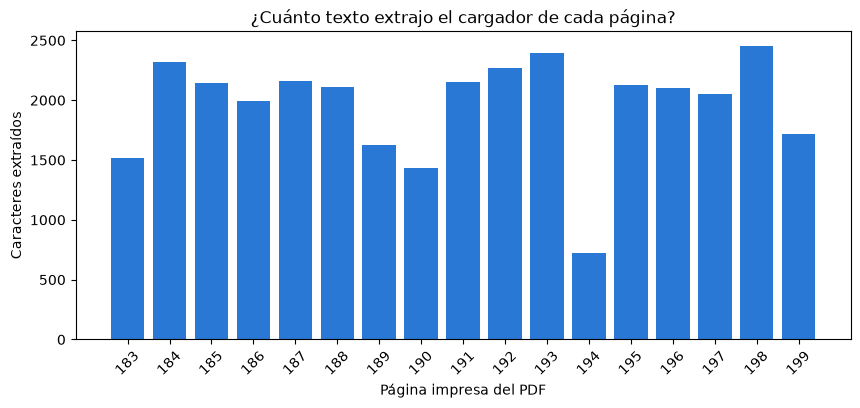

In [5]:
numeros_de_pagina = []
caracteres_por_pagina = []

for pagina in paginas_del_capitulo:
    numeros_de_pagina.append(pagina.metadata["page"] + 1)
    caracteres_por_pagina.append(len(pagina.page_content))

plt.figure(figsize=(10, 4))
plt.bar(numeros_de_pagina, caracteres_por_pagina, color="#2a78d6")
plt.title("¿Cuánto texto extrajo el cargador de cada página?")
plt.xlabel("Página impresa del PDF")
plt.ylabel("Caracteres extraídos")
plt.xticks(numeros_de_pagina, rotation=45)
plt.show()

## 5. Comparar dos formas de fragmentar

No hay un tamaño universal. Vamos a mantener el mismo corpus y comparar dos decisiones.

| Versión | `chunk_size` | `chunk_overlap` | Pregunta para inspeccionar |
|---|---:|---:|---|
| Breve | 500 | 80 | ¿Qué son los embeddings según el capítulo? |
| Amplia | 1.100 | 180 | ¿Qué son los embeddings según el capítulo? |

`chunk_size` y `chunk_overlap` se miden en caracteres. El solapamiento conserva una porción del final de un fragmento al comienzo del siguiente. Probá cambiar **un valor por vez** y anotá qué condición deja de verse completa.

In [6]:
TAMANO_BREVE = 500
SOLAPAMIENTO_BREVE = 80
TAMANO_AMPLIO = 1100
SOLAPAMIENTO_AMPLIO = 180

divisor_breve = RecursiveCharacterTextSplitter(
    chunk_size=TAMANO_BREVE,
    chunk_overlap=SOLAPAMIENTO_BREVE,
)
divisor_amplio = RecursiveCharacterTextSplitter(
    chunk_size=TAMANO_AMPLIO,
    chunk_overlap=SOLAPAMIENTO_AMPLIO,
)

fragmentos_breves = divisor_breve.split_documents(paginas_del_capitulo)
fragmentos_amplios = divisor_amplio.split_documents(paginas_del_capitulo)

print("Fragmentos breves:", len(fragmentos_breves))
print("Fragmentos amplios:", len(fragmentos_amplios))
print("Primer fragmento breve:\n", fragmentos_breves[0].page_content[:500])

Fragmentos breves: 87
Fragmentos amplios: 44
Primer fragmento breve:
 183
CÓMO HABLAN LAS MÁQUINAS ESPAÑOL: 
LOGROS, RETOS Y OPORTUNIDADES PARA  
LA INTELIGENCIA ARTIFICIAL 
APLICADA AL LENGUAJE
ELENA GONZÁLEZ-BLANCO GARCÍA
Banco Santander, LLYC e IE Business School
SALVADOR ROS MUÑOZ
Universidad Nacional de Educación a Distancia (UNED)
VÍCTOR FRESNO FERNÁNDEZ  
Universidad Nacional de Educación a Distancia (UNED)
1 | Los orígenes
Parece que uno de los logros más novedosos hoy es haber conseguido inte-


In [7]:
pregunta_de_comparacion = "¿Qué son los embeddings según el capítulo?"
embeddings = OllamaEmbeddings(model=MODELO_EMBEDDINGS)

vector_pregunta = embeddings.embed_query(pregunta_de_comparacion)
vector_breve = embeddings.embed_query(fragmentos_breves[10].page_content)
vector_amplio = embeddings.embed_query(fragmentos_amplios[5].page_content)

print("Dimensiones del vector de la pregunta:", len(vector_pregunta))
print("Dimensiones del vector breve:", len(vector_breve))
print("Dimensiones del vector amplio:", len(vector_amplio))
print("Los tres vectores deben tener la misma dimensión porque usan bge-m3.")

Dimensiones del vector de la pregunta: 1024
Dimensiones del vector breve: 1024
Dimensiones del vector amplio: 1024
Los tres vectores deben tener la misma dimensión porque usan bge-m3.


La celda anterior no decide cuál fragmento es mejor: sólo comprueba que la pregunta y ambos textos se representan con el mismo modelo. Ahora construimos dos índices temporales en memoria para comparar la evidencia recuperada. La distancia menor indica mayor cercanía según esta colección; no es una probabilidad de verdad.

In [8]:
indice_breve = Chroma.from_documents(
    documents=fragmentos_breves,
    embedding=embeddings,
    collection_name="laboratorio_comparacion_breve",
)
indice_amplio = Chroma.from_documents(
    documents=fragmentos_amplios,
    embedding=embeddings,
    collection_name="laboratorio_comparacion_amplio",
)

hallazgo_breve = indice_breve.similarity_search_with_score(
    query=pregunta_de_comparacion,
    k=1,
)[0]
hallazgo_amplio = indice_amplio.similarity_search_with_score(
    query=pregunta_de_comparacion,
    k=1,
)[0]

for nombre, hallazgo in [("Breve", hallazgo_breve), ("Amplio", hallazgo_amplio)]:
    documento, distancia = hallazgo
    print(f"\n{nombre} — página {documento.metadata['page'] + 1}")
    print("Distancia:", round(distancia, 3))
    print(documento.page_content)


Breve — página 192
Distancia: 0.884
produciendo y los traduzca a vectores llamados embeddings, que aproximan 
la semántica de las palabras, las frases o los documentos. Esto no son más que 
representaciones de conceptos más o menos complicados (es decir, palabras, 
frases o textos) en un espacio en el cual podemos establecer relaciones lógi-
cas semánticas a partir del isomorfismo semántico generado en este espacio 
de representación; es decir, asumiendo que las relaciones dentro del espacio

Amplio — página 192
Distancia: 0.933
representaciones de conceptos más o menos complicados (es decir, palabras, 
frases o textos) en un espacio en el cual podemos establecer relaciones lógi-
cas semánticas a partir del isomorfismo semántico generado en este espacio 
de representación; es decir, asumiendo que las relaciones dentro del espacio 
de los embeddings mantienen las relaciones semánticas originales entre los 
conceptos representados por dichas palabras. Por supuesto, esta frase supone 
un

### Actividad 1 — Elegir un corte

Leé ambos resultados y completá esta frase en una celda Markdown propia: «Para la pregunta sobre embeddings, elegiría el corte ___ porque ___. El riesgo que observo es ___». Después cambiá `TAMANO_BREVE` a 300 **o** `SOLAPAMIENTO_BREVE` a 0 y repetí sólo las celdas de fragmentación y comparación.

## 6. Construir un índice persistente para el RAG

El siguiente bloque reconstruye deliberadamente **su propia colección** cada vez que lo ejecutás. Así evitamos que un índice conserve fragmentos de una configuración anterior. No borra `chroma_db/` ni el índice de los otros cuadernos.

In [9]:
CARPETA_INDICE = "chroma_db_laboratorio_espanol"
NOMBRE_COLECCION = "espanol_mundo_paginas_183_199_bge_m3"

indice_rag = Chroma(
    collection_name=NOMBRE_COLECCION,
    embedding_function=embeddings,
    persist_directory=CARPETA_INDICE,
)

if indice_rag.get(limit=1)["ids"]:
    indice_rag.delete_collection()
    indice_rag = Chroma(
        collection_name=NOMBRE_COLECCION,
        embedding_function=embeddings,
        persist_directory=CARPETA_INDICE,
    )

identificadores = []
for numero in range(len(fragmentos_breves)):
    identificadores.append(f"pagina_fragmento_{numero}")

indice_rag.add_documents(documents=fragmentos_breves, ids=identificadores)
print("Fragmentos indexados:", len(indice_rag.get()["ids"]))

Fragmentos indexados: 87


## 7. Recuperar evidencia antes de generar

Empezamos con una pregunta verificable: el capítulo señala que el español supera los 595 millones de hablantes. Mirá el contenido del fragmento, no sólo su distancia o su número de página.

In [10]:
pregunta = "¿Cuántos hablantes de español menciona el capítulo y qué porcentaje mundial representa?"
K = 3
hallazgos = indice_rag.similarity_search_with_score(query=pregunta, k=K)

contexto = ""
referencias = []

for numero, hallazgo in enumerate(hallazgos, start=1):
    documento, distancia = hallazgo
    pagina_impresa = documento.metadata["page"] + 1
    referencia = f"{RUTA_PDF.name}, página {pagina_impresa}"
    referencias.append(referencia)
    contexto += f"[{numero}] {referencia}\n{documento.page_content}\n\n"
    print(f"\n[{numero}] {referencia} — distancia {distancia:.3f}")
    print(documento.page_content[:500])

print("\nContexto completo enviado al modelo:\n", contexto)


[1] espanol_en_el_mundo.pdf, página 196 — distancia 0.785
Ante esta situación, no podemos olvidar que «…[e]l español es la segunda 
lengua materna del mundo por número de hablantes, tras el chino manda -
rín, y la cuarta lengua en un cómputo global de hablantes (dominio nativo 
+ competencia limitada + estudiantes de español), después del inglés, el 
chino mandarín y el hindi», con más de 595 millones de hablantes, lo que 
supone un 7,5 % de la población mundial (Instituto Cervantes, 2022). A

[2] espanol_en_el_mundo.pdf, página 196 — distancia 0.796
supone un 7,5 % de la población mundial (Instituto Cervantes, 2022). A 
pesar de la influencia de este idioma a nivel global, su uso en los nuevos 
paradigmas computacionales orientados a la inteligencia artificial queda 
relegado por el uso del idioma inglés. Esto significa que las soluciones en 
esta área tienen un gran sesgo cultural anglosajón y, por tanto, su eficacia 
en el mundo hispanohablante es menor. También implica una pérdida

## 8. Generar sin ocultar la evidencia

La cadena tiene tres pasos explícitos: plantilla → modelo → texto. El recuperador queda fuera para que podamos inspeccionarlo. La instrucción pide abstención, pero el prompt no es una garantía: vamos a probarlo después.

In [11]:
plantilla = ChatPromptTemplate.from_messages([
    (
        "system",
        "Respondé en español con una oración completa y sólo con la evidencia "
        "del contexto. Citá [1], [2] o [3] junto a cada afirmación. Si el dato "
        "no está en el contexto, respondé exactamente: No encuentro esa "
        "información en los documentos.",
    ),
    ("human", "Contexto:\n{contexto}\n\nPregunta: {pregunta}"),
])

modelo = ChatOllama(model=MODELO_GENERADOR, temperature=0)
cadena_rag = plantilla | modelo | StrOutputParser()
respuesta = cadena_rag.invoke({"contexto": contexto, "pregunta": pregunta})

print("Respuesta:\n", respuesta)
print("\nFuentes que recibió el modelo:")
for referencia in referencias:
    print("-", referencia)

Respuesta:
 El capítulo menciona que el español es la segunda lengua materna del mundo por número de hablantes, tras el chino mandarin, y la cuarta lengua en un cómputo global de hablantes (dominio nativo + competencia limitada + estudiantes de español), después del inglés, el chino mandarin y el hindi, con más de 595 millones de hablantes, lo que supone un 7,5% de la población mundial (Instituto Cervantes, 2022).

Fuentes que recibió el modelo:
- espanol_en_el_mundo.pdf, página 196
- espanol_en_el_mundo.pdf, página 196
- espanol_en_el_mundo.pdf, página 198


## 9. Laboratorio de fallas

Cada caso pone a prueba una parte distinta. Antes de ejecutar, anticipá qué fragmento tendría que aparecer y qué podría salir mal.

| Caso | Qué debería ocurrir | Posible falla |
|---|---|---|
| Embeddings | Recuperar la explicación de las páginas 192–193. | Corte que separa definición y condición. |
| Español y hablantes | Recuperar la página 196. | Confundir una cifra o una fecha. |
| Presupuesto anual de un museo | Abstenerse. | Chroma devuelve vecinos aunque no haya respuesta. |
| ¿Las máquinas entienden igual que las personas? | Reconocer que la pregunta exige interpretación. | Convertir una discusión del texto en certeza. |

In [12]:
casos_de_prueba = [
    "¿Qué son los embeddings según el capítulo?",
    "¿Cuántos hablantes de español menciona el capítulo?",
    "¿Cuál es el presupuesto anual de un museo?",
    "¿Las máquinas entienden igual que las personas?",
]

for caso in casos_de_prueba:
    hallazgos = indice_rag.similarity_search_with_score(query=caso, k=K)
    contexto_del_caso = ""

    for numero, hallazgo in enumerate(hallazgos, start=1):
        documento, _ = hallazgo
        pagina = documento.metadata["page"] + 1
        contexto_del_caso += f"[{numero}] Página {pagina}\n{documento.page_content}\n\n"

    respuesta_del_caso = cadena_rag.invoke(
        {"contexto": contexto_del_caso, "pregunta": caso}
    )
    paginas = [hallazgo[0].metadata["page"] + 1 for hallazgo in hallazgos]
    print("\nPregunta:", caso)
    print("Respuesta:", respuesta_del_caso)
    print("Páginas recuperadas:", paginas)


Pregunta: ¿Qué son los embeddings según el capítulo?
Respuesta: Según el capítulo, los embeddings son representaciones de conceptos más o menos complicados, como palabras, frases o textos, en un espacio en el cual se pueden establecer relaciones lógicas semánticas a partir del isomorfismo semántico generado en este espacio de representación. Esto significa que asumiendo que las relaciones dentro del espacio de los embeddings mantienen las relaciones semánticas originales entre los conceptos representados por dichas palabras. [1][2][3]
Páginas recuperadas: [192, 192, 192]

Pregunta: ¿Cuántos hablantes de español menciona el capítulo?
Respuesta: El capítulo menciona que el español tiene más de 595 millones de hablantes, lo que supone un 7,5% de la población mundial. [1][2]
Páginas recuperadas: [196, 196, 198]

Pregunta: ¿Cuál es el presupuesto anual de un museo?
Respuesta: No encuentro esa información en los documentos.
Páginas recuperadas: [197, 197, 197]

Pregunta: ¿Las máquinas entie

### Actividad 2 — Diagnóstico

Elegí un caso y completá esta tabla en una celda Markdown propia.

| Pregunta | ¿Llegó evidencia pertinente? | ¿La respuesta la interpretó bien? | Diagnóstico | Cambio que probarías |
|---|---|---|---|---|
| Completá | Sí / No | Sí / No | Extracción / corte / recuperación / generación | Completá |

No cambies tres variables juntas. Elegí sólo `chunk_size`, `chunk_overlap`, `K` o la redacción del prompt, repetí la consulta y registrá el antes y el después.

## 10. Darle una interfaz al mismo RAG

La función recupera primero, construye un contexto con páginas y luego genera. Gradio llama a **esa misma función**. La segunda salida no es una cita inventada por el modelo: muestra los fragmentos que efectivamente entraron al contexto.

In [13]:
def consultar(pregunta_usuario: str) -> tuple[str, str]:
    """Responde una pregunta y devuelve los fragmentos usados como evidencia.

    Args:
        pregunta_usuario: Consulta escrita en la interfaz.

    Returns:
        Respuesta del modelo y evidencia recuperada con páginas.
    """
    if not pregunta_usuario.strip():
        return "Escribí una pregunta.", "Todavía no se consultaron fuentes."

    hallazgos = indice_rag.similarity_search_with_score(
        query=pregunta_usuario,
        k=K,
    )
    contexto_usuario = ""
    fuentes = ""

    for numero, hallazgo in enumerate(hallazgos, start=1):
        documento, distancia = hallazgo
        pagina = documento.metadata["page"] + 1
        referencia = f"{RUTA_PDF.name}, página {pagina}"
        contexto_usuario += f"[{numero}] {referencia}\n{documento.page_content}\n\n"
        fuentes += f"**[{numero}] {referencia}** (distancia {distancia:.3f})\n\n"
        fuentes += f"```text\n{documento.page_content}\n```\n\n"

    respuesta_usuario = cadena_rag.invoke(
        {"contexto": contexto_usuario, "pregunta": pregunta_usuario}
    )
    return respuesta_usuario, fuentes


respuesta_de_prueba, fuentes_de_prueba = consultar(
    "¿Qué tarea cumple la lematización?"
)
print(respuesta_de_prueba)
print(fuentes_de_prueba[:900])

La lematización cumple la tarea de encontrar el lema de una palabra, dado su forma flexionada. Esto se menciona en [1] donde se afirma que la lematización es un proceso lingüístico que consiste en encontrar el lema de una palabra, dada su forma flexionada.
**[1] espanol_en_el_mundo.pdf, página 191** (distancia 0.740)

```text
191
raíz) o la lematización (proceso lin -
güístico que consiste en encontrar 
el lema de una palabra, dada su for-
ma flexionada) se pueden considerar 
maduras y sólidas. La complejidad 
de las tareas aumenta cuando se en-
tra a considerar los niveles semánti-
cos. Aquí podemos encontrar tareas 
como el Reconocimiento de Entida-
des Nombradas (NER por su sigla 
en inglés), cuyo objetivo es identi -
ficar personas, organizaciones o lu-
gares, entre otros tipos, de tal ma -
```

**[2] espanol_en_el_mundo.pdf, página 192** (distancia 1.067)

```text
produciendo y los traduzca a vectores llamados embeddings, que aproximan 
la semántica de las palabras, las frases o l

In [14]:
interfaz = gr.Interface(
    fn=consultar,
    inputs=gr.Textbox(label="Pregunta sobre las páginas 183 a 199"),
    outputs=[
        gr.Textbox(label="Respuesta"),
        gr.Markdown(label="Fragmentos recuperados y enviados al modelo"),
    ],
    title="RAG local: cómo hablan las máquinas",
    description=(
        "Laboratorio sobre un recorte de El español en el mundo. "
        "Verificá cada respuesta contra los fragmentos y el PDF original."
    ),
)

# Ejecutá esta última línea para abrir la interfaz. Detené la celda al terminar.
interfaz.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


## Transferencia al Trabajo Integrador 2

Este laboratorio trabaja un único documento que no se publica como corpus del proyecto. Para el integrador vas a necesitar al menos tres documentos reales y compartibles. Conservá esta tabla como punto de partida.

| Documento propio | Pregunta respondible | Página o sección esperada | ¿Qué recuperó? | ¿Qué interpretó el modelo? | Límite observado |
|---|---|---|---|---|---|
| Completá | Completá | Completá | Completá | Completá | Completá |
| Completá | Completá | Completá | Completá | Completá | Completá |
| Completá | Completá | Completá | Completá | Completá | Completá |

## Glosario

| Término | Qué significa en este laboratorio |
|---|---|
| **Documento** | Texto y metadatos de una página cargada con LangChain. |
| **Metadato** | Dato de procedencia, como el archivo y el índice de página. |
| **Fragmento** | Parte de una página que se puede representar y recuperar por separado. |
| **Embedding** | Vector que el modelo `bge-m3` usa para comparar significados. |
| **Chroma** | Base vectorial que conserva fragmentos, vectores y metadatos. |
| **k** | Cantidad de fragmentos recuperados para armar el contexto. |
| **RAG** | Recuperación de evidencia seguida de generación con ese contexto. |
| **Abstención** | Reconocimiento de que el contexto no alcanza para responder. |
| **Trazabilidad** | Posibilidad de volver desde una respuesta hasta el fragmento y la página original. |